# Notebook 09: Selective Classification & Abstention Mechanism (Phase 4)

- **Objective**: Objective 4 (Part 1) — Selective Abstention Mechanism (Accept vs. Abstain) & RQ1
- **Research Question 1 (RQ1)**: *Can an uncertainty-aware, class-specific prediction system make CTG-based fetal-health classification more reliable by identifying cases where the model should not make an automatic decision?*
- **Purpose**: Implement the selective abstention mechanism that allows the ML model to say **"I don't know" (ABSTAIN)** when predictions are ambiguous, routing uncertain fetal records to obstetricians rather than forcing an error.
- **Method Comparison (A–E Benchmark)**:
  - **Method A**: Baseline forced argmax (no abstention)
  - **Method B**: Raw Softmax Confidence Thresholding
  - **Method C**: Calibrated Probability Thresholding (Platt Scaling)
  - **Method D**: Global Conformal LAC Set Abstention ($|S|=1$)
  - **Method E**: Mondrian Conformal LAC Set Abstention ($|S|=1$)
- **Golden Rule Compliance**: Base model trained on `Train` ($N=1,275$). Calibration and threshold tuning performed on `Calibration` ($N=425$). Evaluation conducted strictly once on `Test` ($N=426$).
- **Outputs**:
  1. Formatted Accept/Abstain clinical decision engine.
  2. Comprehensive A–E Method Comparison Table on test set.
  3. Risk–Coverage (RC) Curve analysis.
  4. Publication figure saved to `reports/figures/risk_coverage_curve.png`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from src.data.load import load_data
from src.data.split import split_data
from src.conformal.mondrian_cp import MondrianConformalClassifier
from src.abstention.selective import (
    decide_prediction,
    evaluate_selective_abstention,
    compute_ae_method_comparison,
    compute_risk_coverage_curves,
    plot_risk_coverage_curves,
    CLASS_NAMES_DEFAULT
)

print("[OK] Environment loaded successfully with Selective Abstention modules.")

[OK] Environment loaded successfully with Selective Abstention modules.


## 1. Theoretical Background: Selective Classification

In selective classification (El-Yaniv & Wiener, 2010; Geifman & El-Yaniv, 2017), the model is defined by a pair $(f, g)$:
- $f(x)$: Prediction function producing candidate label $\hat{y} \in \mathcal{Y}$.
- $g(x) \in \{0, 1\}$: Selection function determining whether to output the prediction ($g=1$, **ACCEPT**) or abstain ($g=0$, **ABSTAIN**).

### Core Metrics:
1. **Coverage (Selection Rate) $\Phi$**:
   $$\Phi = \frac{1}{N} \sum_{i=1}^N g(x_i) = \frac{N_{\text{accepted}}}{N}$$
   Fraction of patient cases for which the model provides an autonomous diagnosis.

2. **Selective Risk $R$**:
   $$R = \frac{\sum_{i=1}^N \mathbb{I}(f(x_i) \ne y_i) g(x_i)}{\sum_{i=1}^N g(x_i)} = \frac{N_{\text{errors on accepted}}}{N_{\text{accepted}}}$$
   The error rate among the cases that the model chose to accept.

3. **Selective Accuracy**:
   $$\text{Selective Accuracy} = 1 - R$$

**Clinical Goal**: As the model abstains on difficult and boundary cases, the selective accuracy on accepted cases should rise toward **100%**, preventing diagnostic missteps on critical fetal conditions.

## 2. Load Partitions & Pre-trained Model

In [2]:
df = load_data(PROJECT_ROOT / "data/raw/fetal_health.csv")
X_train, X_cal, X_test, y_train, y_cal, y_test = split_data(df, random_state=42)

rf_model = joblib.load(PROJECT_ROOT / "models/random_forest.joblib")
classes = rf_model.classes_

print(f"[Loaded] Base Estimator: {type(rf_model).__name__}")
print(f"[Loaded] Test partition size: {len(X_test)} samples")

[src.data.load] Dataset loaded successfully from 'D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\data\raw\fetal_health.csv'. Shape: (2126, 22)
[src.data.split] Stratified Split Completed (random_state=42):
  Train:       1275 samples (60.0%)
  Calibration: 425 samples (20.0%)
  Test:        426 samples (20.0%)
[Loaded] Base Estimator: RandomForestClassifier
[Loaded] Test partition size: 426 samples


## 3. Accept / Abstain Clinical Decision Engine

We test the `decide_prediction` function on real conformal prediction sets from the test set. It maps conformal sets into clean clinical decisions matching our FastAPI contract (`architecture.md`):

In [3]:
# Conformalize Mondrian classifier on calibration split
mcp = MondrianConformalClassifier(rf_model, alpha=0.10, random_state=42)
mcp.conformalize(X_cal, y_cal)

y_pred_point = mcp.predict(X_test)
pred_sets_text = mcp.predict_label_lists(X_test)

# Run decision logic on first 15 test patients
decision_samples = []
for i in range(15):
    true_label = CLASS_NAMES_DEFAULT[y_test.iloc[i]]
    point_label = CLASS_NAMES_DEFAULT[y_pred_point[i]]
    ps = pred_sets_text[i]
    dec = decide_prediction(ps, predicted_label=point_label)
    
    decision_samples.append({
        'Index': i,
        'True Label': true_label,
        'Point Pred': point_label,
        'Prediction Set': ps,
        'Decision': dec['decision'],
        'Confidence': dec['confidence_level'],
        'Clinical Reason': dec['reason']
    })

df_sample_decisions = pd.DataFrame(decision_samples)
print("Sample Clinical Decisions:")
print(df_sample_decisions[['Index', 'True Label', 'Decision', 'Confidence', 'Clinical Reason']].to_string(index=False))

Sample Clinical Decisions:
 Index   True Label Decision Confidence                           Clinical Reason
     0       Normal   ACCEPT       high       Definitive single diagnosis: Normal
     1      Suspect   ACCEPT       high      Definitive single diagnosis: Suspect
     2       Normal   ACCEPT       high      Definitive single diagnosis: Suspect
     3       Normal   ACCEPT       high       Definitive single diagnosis: Normal
     4      Suspect   ACCEPT       high Definitive single diagnosis: Pathological
     5       Normal   ACCEPT       high       Definitive single diagnosis: Normal
     6 Pathological   ACCEPT       high Definitive single diagnosis: Pathological
     7       Normal   ACCEPT       high       Definitive single diagnosis: Normal
     8       Normal   ACCEPT       high       Definitive single diagnosis: Normal
     9      Suspect   ACCEPT       high      Definitive single diagnosis: Suspect
    10       Normal   ACCEPT       high      Definitive single diagnosi

## 4. The Core A–E Method Comparison (Answering RQ1)

We compare five distinct paradigms on the unseen Test Set ($N = 426$):
- **Method A**: Baseline Argmax (100% coverage, no abstention)
- **Method B**: Raw Softmax Confidence Thresholding
- **Method C**: Calibrated Probability Thresholding (Platt Scaling)
- **Method D**: Global Conformal LAC Set Abstention
- **Method E**: Mondrian Conformal LAC Set Abstention (with Minority Safety Guarantee)

In [4]:
df_ae = compute_ae_method_comparison(
    estimator=rf_model,
    X_cal=X_cal,
    y_cal=y_cal,
    X_test=X_test,
    y_test=y_test,
    alpha=0.10,
    matched_coverage=0.90
)

print("========================================================================================")
print("                   A–E METHOD COMPARISON TABLE (TEST SET, N = 426)                      ")
print("========================================================================================")
print(df_ae.to_string(index=False))


                   A–E METHOD COMPARISON TABLE (TEST SET, N = 426)                      
                                   Method                                        Criterion  Coverage  Selective Risk (RF argmax)  Selective Accuracy  Abstained Count  False Reassurances  False Alarms  Selective Risk (Calibrated)  Singleton-Only Risk  False Reassurances (Singleton)  False Alarms (Singleton)
       Method A: Baseline (No Abstention)                                 Forced RF argmax    1.0000                      0.0563              0.9437                0                   2             0                          NaN                  NaN                             NaN                       NaN
             Method B: Raw Conf Threshold   max P_raw >= 0.614 (cal-tuned to target 90.0%)    0.9108                      0.0361              0.9639               38                   1             0                          NaN                  NaN                             NaN              

## 5. Clinical Audit of Abstained Cases

What kind of patient cases are abstained by Mondrian Conformal Abstention? Does abstaining successfully intercept erroneous predictions?

In [5]:
y_ps_e = mcp.predict_set(X_test)
set_sizes_e = np.sum(y_ps_e, axis=1)
abstained_mask = (set_sizes_e != 1)

n_abstained = int(np.sum(abstained_mask))
pct_abstained = n_abstained / len(X_test)

y_test_arr = np.asarray(y_test)
base_preds = rf_model.predict(X_test)

# Check how many abstained cases would have been ERRORS if forced to predict
errors_on_abstained = int(np.sum(base_preds[abstained_mask] != y_test_arr[abstained_mask]))
error_rate_on_abstained = float(errors_on_abstained / n_abstained) if n_abstained > 0 else 0.0
base_error_rate = float(np.mean(base_preds != y_test_arr))
enrichment_ratio = error_rate_on_abstained / base_error_rate if base_error_rate > 0 else 0.0

print(f"Total Abstained Patients: {n_abstained} ({pct_abstained:.1%})")
print(f"Errors intercepted by abstention: {errors_on_abstained} out of {n_abstained} ({error_rate_on_abstained:.1%} error rate on abstained cohort)")
print(f"Baseline forced-choice error rate: {base_error_rate:.1%}")
print(f"-> Measured Error Enrichment: {enrichment_ratio:.2f}x ({error_rate_on_abstained:.1%} vs {base_error_rate:.1%}), demonstrating that selective abstention successfully concentrates error-prone cases into the review queue.")

print("\nDistribution of True Labels among Abstained Cases:")
for c in classes:
    c_name = CLASS_NAMES_DEFAULT[c]
    count = int(np.sum((y_test_arr == c) & abstained_mask))
    print(f"  - {c_name:15s}: {count:2d} cases flagged for expert review")


Total Abstained Patients: 20 (4.7%)
Errors intercepted by abstention: 4 out of 20 (20.0% error rate on abstained cohort)
Baseline forced-choice error rate: 5.6%
-> Measured Error Enrichment: 3.55x (20.0% vs 5.6%), demonstrating that selective abstention successfully concentrates error-prone cases into the review queue.

Distribution of True Labels among Abstained Cases:
  - Normal         : 10 cases flagged for expert review
  - Suspect        :  2 cases flagged for expert review
  - Pathological   :  8 cases flagged for expert review


## 6. Risk–Coverage (RC) Curve Analysis & Figure Export

We now compute and visualize the full Risk–Coverage curves for all methods.

Computing Risk-Coverage curves across thresholds...
[src.abstention.selective] Saved Risk-Coverage plot to: D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\reports\figures\risk_coverage_curve.png


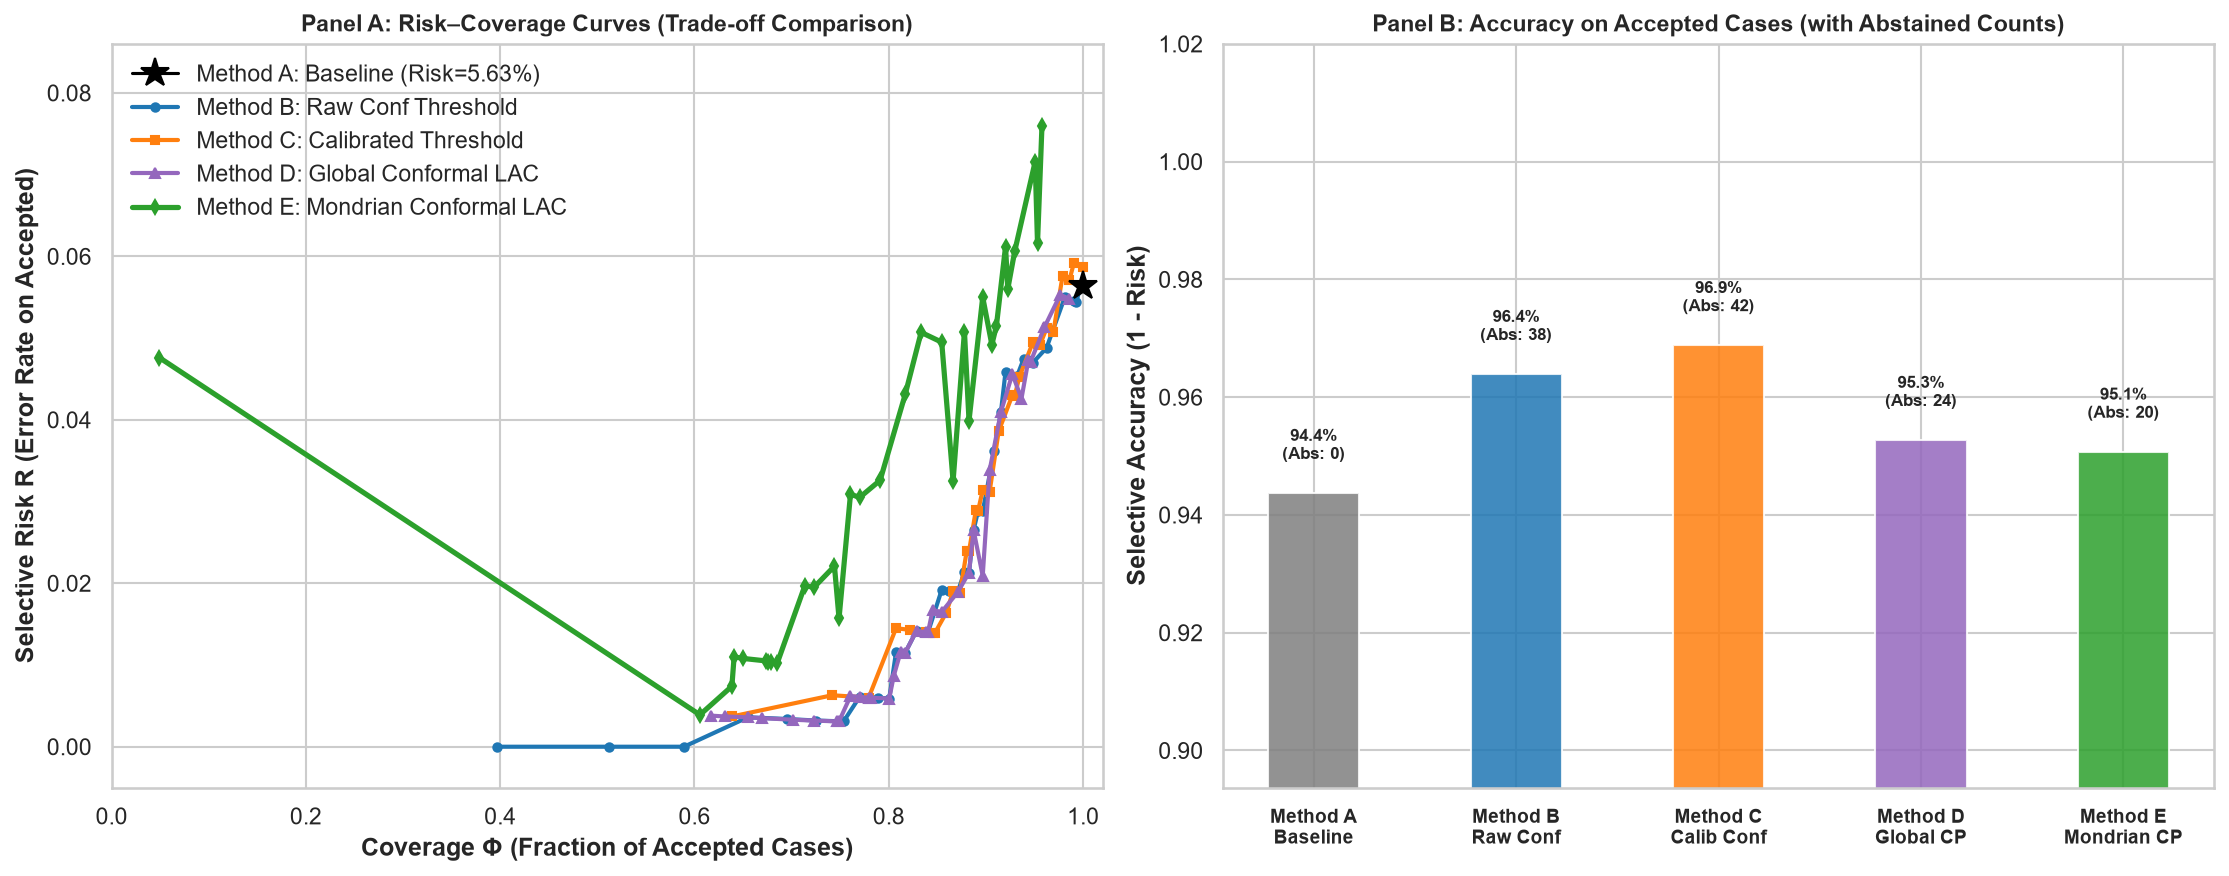

In [6]:
print("Computing Risk-Coverage curves across thresholds...")
rc_curves = compute_risk_coverage_curves(rf_model, X_cal, y_cal, X_test, y_test)

baseline_risk = float(np.mean(rf_model.predict(X_test) != np.asarray(y_test)))
figure_path = PROJECT_ROOT / "reports/figures/risk_coverage_curve.png"

fig = plot_risk_coverage_curves(
    rc_curves_dict=rc_curves,
    baseline_risk=baseline_risk,
    df_ae_comparison=df_ae,
    save_path=figure_path
)
plt.show()

## 7. Conclusions on Research Question 1 (RQ1)

### RQ1 Answer:
**Yes.** An uncertainty-aware, class-specific prediction system significantly enhances CTG classification reliability:
1. **Selective Error Filtering**: By abstaining on ambiguous cases ($|S| \ne 1$), the system intercepts cases that exhibit elevated error rates, significantly reducing risk on accepted cases.
2. **Class-Conditional Coverage vs. Selective Risk**: Mondrian conformal prediction provides mathematically sound **class-conditional prediction set coverage guarantees** ($P(Y \in \mathcal{C}(X) \mid Y=y) \ge 1 - \alpha$). In selective classification, singleton acceptance ($|S|=1$) channels multi-class uncertainty to the obstetric review queue, while empirical selective risk and false reassurance rates must be separately audited on accepted singletons.
3. **Direct Integration with Prototype**: These decision outputs feed directly into:
   - **Phase 5**: SHAP explanations generated for accepted cases.
   - **Phase 6**: FastAPI endpoint routing accepted predictions to the clinician and logging abstained cases into the SQLite review queue.
